<a href="https://colab.research.google.com/github/Rageel-28/244107020136-Machine-Learning/blob/main/JS07/JS07_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS07 - Klasterisasi
## Lab 3 - Klasterisasi pada Kompresi Citra

Klasterisasi tidak hanya dapat digunakan pada data tabular. Pada citra, klasterisasi dapat dipakai untuk mengidentifikasi kesamaan warna sehingga kita mendapatkan area-area tertentu untuk identifikasi lebih lanjut. Kasus lainnya adalah **kompresi warna citra**: kita meminimalkan jumlah warna yang digunakan untuk mendapatkan citra dengan ukuran data yang lebih kecil.

## Langkah 0 - Import Library

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Langkah 1 - Load Data Citra

Kita menggunakan 1 citra dari dataset contoh yang disediakan `scikit-learn`.

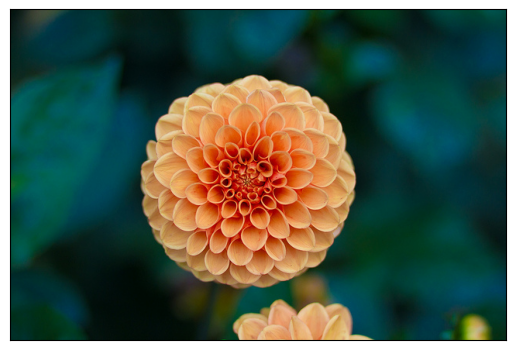

In [2]:
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)
plt.show()

## Langkah 2 - Preprocessing

Cek ukuran citra, normalisasi warna ke rentang 0-1, lalu *reshape* menjadi data 2 dimensi (setiap baris = 1 piksel dengan 3 nilai R, G, B).

In [3]:
# Check shape
print(flower.shape)

# Normalize color
data = flower / 255.0

# Reshape
data = data.reshape(427 * 640, 3)  # turn to 1D

print(data.shape)

(427, 640, 3)
(273280, 3)


## Langkah 3 - Cek Sebaran Warna

Buat fungsi untuk memplot sebaran warna piksel (diambil subset acak agar ringan).

In [4]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

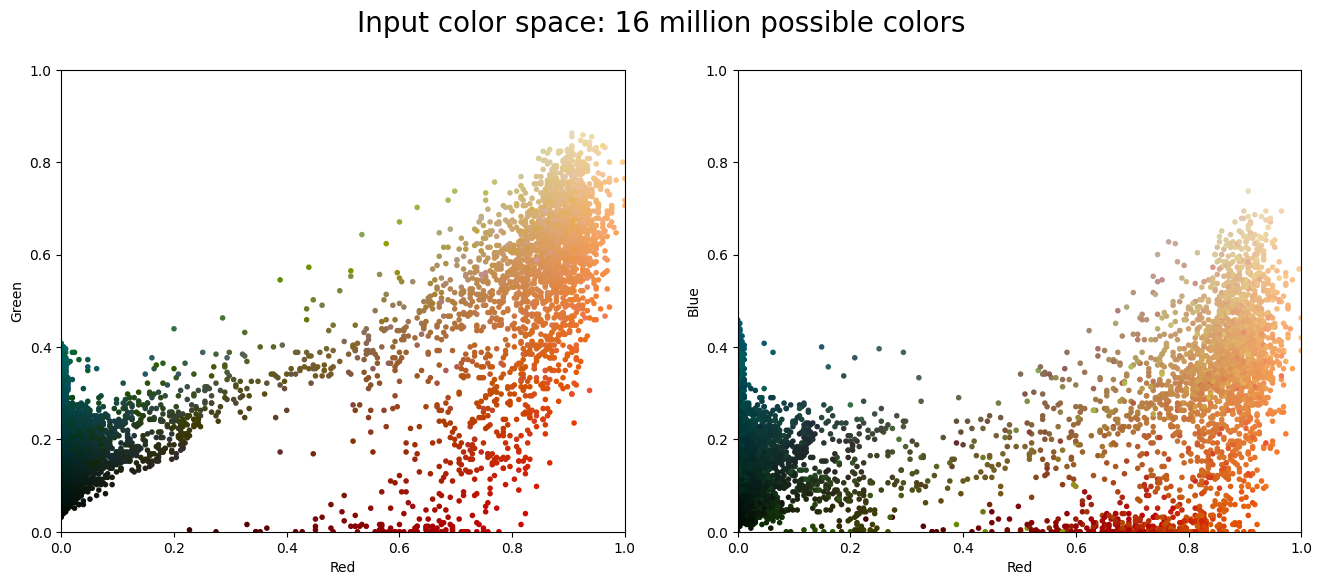

In [5]:
plot_pixels(data, title='Input color space: 16 million possible colors')
plt.show()

## Langkah 4 - Klasterisasi Warna

Pada tahap ini kita melakukan klasterisasi sehingga citra hanya menggunakan **16 warna**. Kita memakai `MiniBatchKMeans` karena lebih cepat untuk data besar (±273 ribu piksel). Warna setiap piksel diganti dengan warna centroid *cluster*-nya.

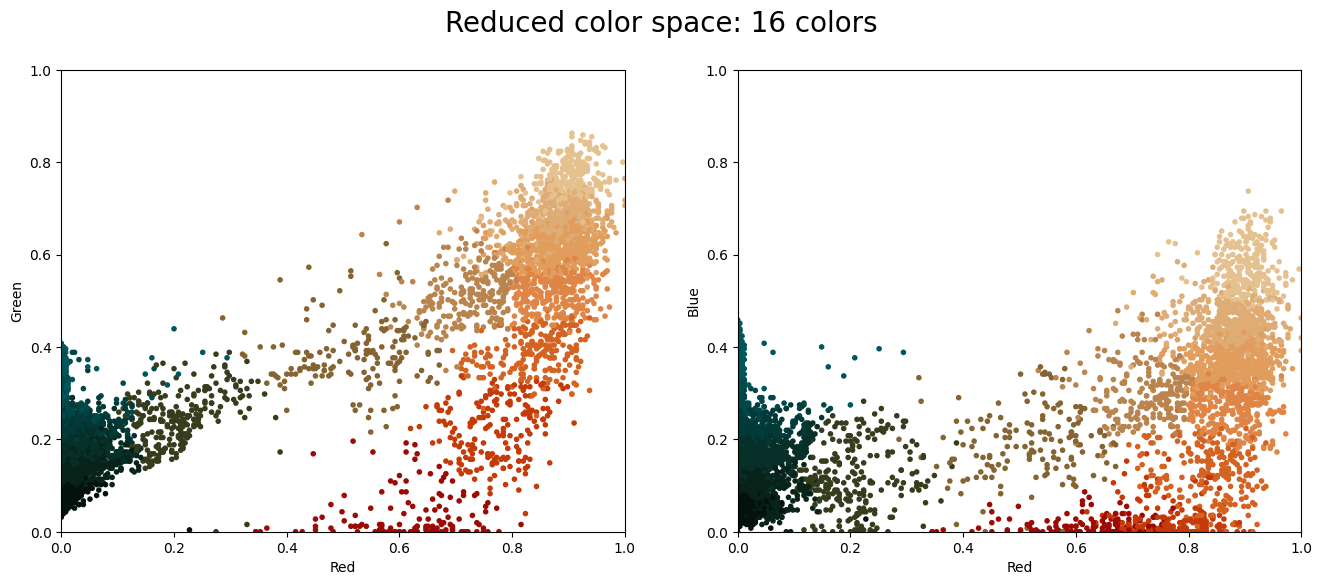

In [6]:
from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(16, random_state=0)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors, title="Reduced color space: 16 colors")
plt.show()

Perbandingan citra sebelum dan sesudah kompresi warna:

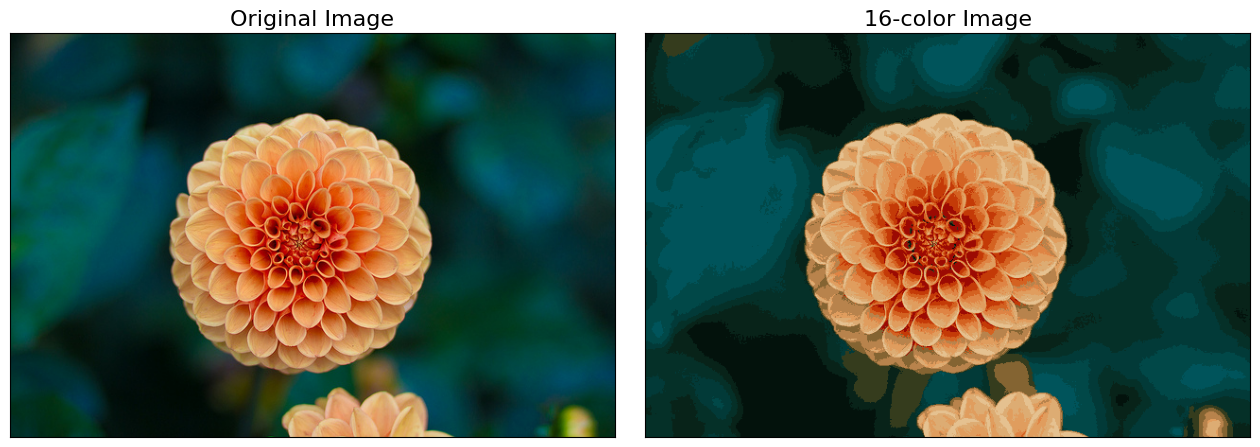

In [7]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);
plt.show()

## Tambahan - Seberapa Besar Reduksinya?

In [8]:
warna_asli = len(np.unique(flower.reshape(-1, 3), axis=0))
warna_baru = len(np.unique(np.round(new_colors, 6), axis=0))
print(f'Jumlah warna unik citra asli : {warna_asli}')
print(f'Jumlah warna unik citra baru : {warna_baru}')
print(f'Reduksi                      : {100 * (1 - warna_baru / warna_asli):.2f}%')

# Perkiraan ukuran data warna: 24 bit/piksel (asli) vs 4 bit/piksel (indeks 16 warna) + palet 16 x 24 bit
piksel = flower.shape[0] * flower.shape[1]
ukuran_asli = piksel * 24 / 8
ukuran_baru = (piksel * 4 + 16 * 24) / 8
print(f'Perkiraan ukuran asli        : {ukuran_asli / 1024:.1f} KB')
print(f'Perkiraan ukuran 16 warna    : {ukuran_baru / 1024:.1f} KB')

Jumlah warna unik citra asli : 62941
Jumlah warna unik citra baru : 16
Reduksi                      : 99.97%
Perkiraan ukuran asli        : 800.6 KB
Perkiraan ukuran 16 warna    : 133.5 KB


### Analisis

Citra asli memiliki puluhan ribu warna unik (ruang warna 24-bit memungkinkan ±16 juta warna). Setelah klasterisasi K-Means, seluruh piksel dipetakan ke **16 warna centroid** saja, sehingga ukuran data warna berkurang drastis, sementara citra masih dapat dikenali. Jumlah *cluster* ($k$) menjadi pengatur *trade-off* antara kualitas visual dan ukuran data: makin kecil $k$ makin kecil ukuran data tetapi detail warna makin hilang.